In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter

from matplotlib.patches import Patch

sns.set_theme(style="white", context="notebook", rc={
    "figure.facecolor": "white", "axes.facecolor": "white",
    "figure.dpi": 120, "axes.axisbelow": True,
    "axes.edgecolor": "#CBD2D9", "axes.linewidth": 0.8,
    "axes.labelcolor": "#374151", "text.color": "#1F2937",
    "xtick.color": "#4B5563", "ytick.color": "#4B5563",
    "grid.color": "#E9EDF2", "grid.linewidth": 0.6,
    "axes.titleweight": "semibold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.titlepad": 16,
    "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "legend.frameon": False, "patch.linewidth": 0,
})
STATUS_ORDER = ["Stayed", "Left"]
STATUS_COLORS = {"Stayed": "#4C78A8", "Left": "#D97757"}
TOPIC_COLORS = {
    "projects": "#2A9D8F",
    "tenure": "#8172B2",
    "salary": "#B58A35",
    "department": "#607D9C",
}

def style_axes(ax, grid_axis="y"):
    ax.set_axisbelow(True)
    ax.grid(False, which="both")
    if grid_axis is not None:
        ax.grid(True, axis=grid_axis, color="#E9EDF2", linewidth=0.6)
    ax.tick_params(axis="both", length=0, pad=7)
    sns.despine(ax=ax)

# Employee Churn: Exploratory Data Analysis

## 0. Data loading and initial inspection
Check dataset size, missing values and duplicates. `left`: 0 = Stayed, 1 = Left. Run this notebook from the repository root.

Exact duplicate rows are removed, although identical records may represent different employees. Results before and after removal are shown below.

This overview uses the full HR dataset; Sections 1–5 use only `train.csv`. Findings show associations, not causes.

In [2]:
raw_data = pd.read_csv('data/HR_Dataset.csv')
raw_data.columns = raw_data.columns.str.strip()
data = raw_data.copy()

### Column types and observed values (full dataset overview)
Unique categories, observed numeric ranges and 0/1 meanings from `HR_Dataset.csv`.

In [3]:
binary_meanings = {
    "Work_accident": "0 = No recorded accident; 1 = Recorded accident",
    "left": "0 = Stayed; 1 = Left",
    "promotion_last_5years": "0 = Not promoted; 1 = Promoted",
}
column_rows = []
for column in raw_data.columns:
    series = raw_data[column]
    if column in binary_meanings:
        kind = "Binary"
        values = ", ".join(f"{value:g}" for value in sorted(series.dropna().unique()))
        values += f" ({binary_meanings[column]})"
    elif pd.api.types.is_numeric_dtype(series):
        kind = "Numeric"
        values = f"{series.min():g} – {series.max():g}"
    else:
        kind = "Categorical"
        values = ", ".join(str(value) for value in sorted(series.dropna().unique()))
    column_rows.append({"Column": column, "Type": kind, "Data type": str(series.dtype),
                        "Values / range": values, "Missing values": int(series.isna().sum())})
column_values = pd.DataFrame(column_rows)
display(
    column_values.style.hide(axis="index")
    .set_properties(**{"text-align": "left", "vertical-align": "top"})
    .set_properties(subset=["Values / range"], **{"white-space": "normal", "overflow-wrap": "anywhere", "max-width": "700px"})
)

Column,Type,Data type,Values / range,Missing values
satisfaction_level,Numeric,float64,0.09 – 1,0
last_evaluation,Numeric,float64,0.36 – 1,0
number_project,Numeric,int64,2 – 7,0
average_montly_hours,Numeric,int64,96 – 310,0
time_spend_company,Numeric,int64,2 – 10,0
Work_accident,Binary,int64,"0, 1 (0 = No recorded accident; 1 = Recorded accident)",0
left,Binary,int64,"0, 1 (0 = Stayed; 1 = Left)",0
promotion_last_5years,Binary,int64,"0, 1 (0 = Not promoted; 1 = Promoted)",0
Departments,Categorical,object,"IT, RandD, accounting, hr, management, marketing, product_mng, sales, support, technical",0
salary,Categorical,object,"high, low, medium",0


In [4]:
data.isnull().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
Departments              0
salary                   0
dtype: int64

In [5]:
data.duplicated().sum()

np.int64(3008)

Dataset,Employees (n),Employees who left,Churn rate (%)
Before duplicate removal,14999,3571,23.81
After duplicate removal (analysis),11991,1991,16.60


Exact duplicate rows removed: 3,008


,Missing values
satisfaction_level,0
last_evaluation,0
number_project,0
average_montly_hours,0
time_spend_company,0
Work_accident,0
left,0
promotion_last_5years,0
Departments,0
salary,0


,Employees (n),Share (%)
Status,,
Stayed,10000,83.40
Left,1991,16.60


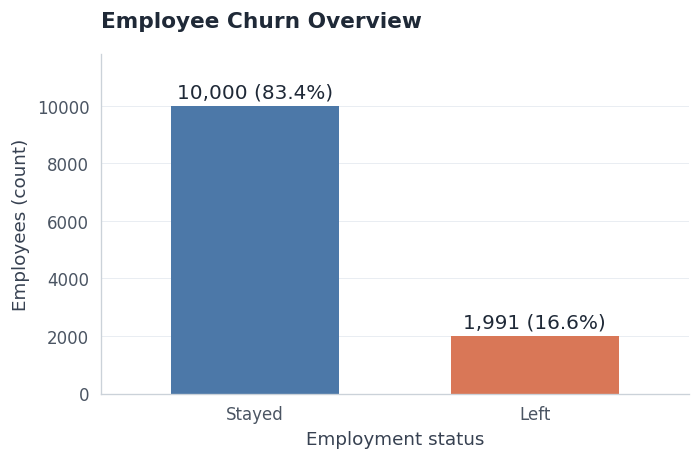

In [6]:
data = data.drop_duplicates().reset_index(drop=True)
assert data["left"].notna().all() and data["left"].isin([0, 1]).all(), "Expected a complete binary left column"
data["Status"] = data["left"].map({0: "Stayed", 1: "Left"})
overall_rate = data["left"].mean() * 100
status_counts = data["Status"].value_counts().reindex(STATUS_ORDER)

overview = pd.DataFrame({
    "Dataset": ["Before duplicate removal", "After duplicate removal (analysis)"],
    "Employees (n)": [len(raw_data), len(data)],
    "Employees who left": [int(raw_data["left"].sum()), int(data["left"].sum())],
    "Churn rate (%)": [raw_data["left"].mean() * 100, overall_rate],
})
display(overview.style.format({"Churn rate (%)": "{:.2f}"}).hide(axis="index"))
print(f"Exact duplicate rows removed: {raw_data.duplicated().sum():,}")
display(raw_data.isna().sum().rename("Missing values").to_frame())

status_summary = status_counts.rename("Employees (n)").to_frame()
status_summary["Share (%)"] = status_summary["Employees (n)"] / len(data) * 100
display(status_summary.style.format({"Share (%)": "{:.2f}"}))
ax = status_counts.plot.bar(color=[STATUS_COLORS[status] for status in STATUS_ORDER], rot=0, width=0.6, edgecolor="none", figsize=(6, 4))
style_axes(ax)
for bar, count in zip(ax.patches, status_counts):
    ax.annotate(f"{count:,} ({count / len(data):.1%})", (bar.get_x() + bar.get_width() / 2, bar.get_height()), xytext=(0, 5), textcoords="offset points", ha="center")
ax.set(title="Employee Churn Overview", xlabel="Employment status", ylabel="Employees (count)")
ax.set_ylim(0, status_counts.max() * 1.18)
plt.tight_layout()
plt.show()

In [7]:
data.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Departments,salary,Status
0,0.38,0.53,2,157,3,0,1,0,sales,low,Left
1,0.80,0.86,5,262,6,0,1,0,sales,medium,Left
2,0.11,0.88,7,272,4,0,1,0,sales,medium,Left
3,0.72,0.87,5,223,5,0,1,0,sales,low,Left
4,0.37,0.52,2,159,3,0,1,0,sales,low,Left


In [8]:
data.shape

(11991, 11)

In [9]:
data.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'Departments', 'salary', 'Status'],
      dtype='object')

In [10]:
data.describe(include="all")

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Departments,salary,Status
count,11991.000000,11991.000000,11991.000000,11991.000000,11991.000000,11991.000000,11991.000000,11991.000000,11991,11991,11991
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,3,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sales,low,Stayed
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3239,5740,10000
mean,0.629658,0.716683,3.802852,200.473522,3.364857,0.154282,0.166041,0.016929,NaN,NaN,NaN
std,0.241070,0.168343,1.163238,48.727813,1.330240,0.361234,0.372133,0.129012,NaN,NaN,NaN
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
25%,0.480000,0.570000,3.000000,157.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
50%,0.660000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
75%,0.820000,0.860000,5.000000,243.000000,4.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN


In [11]:
data["left"].value_counts()

left
0    10000
1     1991
Name: count, dtype: int64

In [12]:
data["left"].value_counts(normalize=True)

left
0    0.833959
1    0.166041
Name: proportion, dtype: float64

**Key takeaway:** The dataset contains 14,999 records, no missing values and 3,008 exact duplicates. Removing duplicates changes the churn rate from 23.8% to 16.6%, making the duplicate-handling assumption important.

## Training data analysis
All analyses below use only `data/train.csv`.

In [13]:
# Replace the overview data with the training split before any feature analysis.
data = pd.read_csv('data/train.csv')
data.columns = data.columns.str.strip()
assert not data.empty, "The training split must not be empty"
assert data["left"].notna().all() and data["left"].isin([0, 1]).all(), "Expected a complete binary left column"
data["Status"] = data["left"].map({0: "Stayed", 1: "Left"})
overall_rate = data["left"].mean() * 100
status_counts = data["Status"].value_counts().reindex(STATUS_ORDER, fill_value=0)
print(f"Analysis dataset: data/train.csv | Employees: {len(data):,} | Churn rate: {overall_rate:.2f}%")
training_summary = status_counts.rename("Employees (n)").to_frame()
training_summary["Share (%)"] = training_summary["Employees (n)"] / len(data) * 100
display(training_summary.style.format({"Share (%)": "{:.2f}"}))

Analysis dataset: data/train.csv | Employees: 8,393 | Churn rate: 16.61%


,Employees (n),Share (%)
Status,,
Stayed,6999,83.39
Left,1394,16.61


## 1. Satisfaction and evaluation
Compare satisfaction and evaluation scores between employees who stayed and left. Each group's histogram sums to 100%; bar heights show the share within that group, not churn rates.

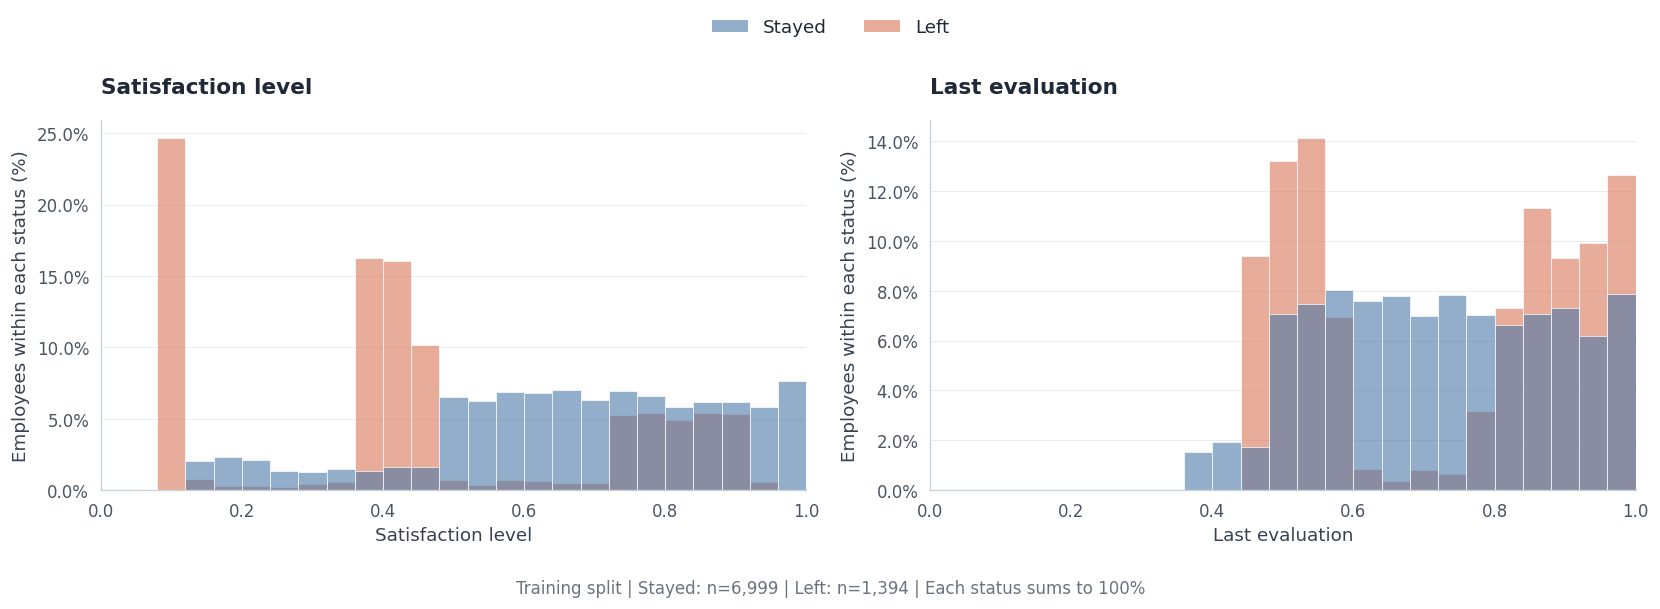

satisfaction_level               last_evaluation              
                    count   mean median           count   mean median
Status                                                               
Stayed               6999  0.666   0.69            6999  0.716   0.71
Left                 1394  0.444   0.41            1394  0.723   0.80

In [14]:
score_columns = {"satisfaction_level": "Satisfaction level", "last_evaluation": "Last evaluation"}
score_bins = np.linspace(0, 1, 26)  # 25 common bins for both statuses
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, (column, label) in zip(axes, score_columns.items()):
    assert data[column].notna().all() and data[column].between(0, 1).all(), f"Invalid scores in {column}"
    sns.histplot(data=data, x=column, hue="Status", hue_order=STATUS_ORDER,
                 bins=score_bins, stat="percent", common_norm=False,
                 multiple="layer", palette=STATUS_COLORS, alpha=0.6,
                 edgecolor="white", linewidth=0.4, legend=False, ax=ax)
    style_axes(ax)
    ax.set(title=label, xlabel=label, ylabel="Employees within each status (%)", xlim=(0, 1))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
fig.legend(handles=[Patch(facecolor=STATUS_COLORS[status], label=status, alpha=0.6) for status in STATUS_ORDER],
           loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.text(0.5, 0.015, f"Training split | Stayed: n={status_counts['Stayed']:,} | Left: n={status_counts['Left']:,} | Each status sums to 100%",
         ha="center", fontsize=10, color="#6B7280")
fig.tight_layout(rect=(0, 0.06, 1, 0.91))
plt.show()

display(data.groupby("Status")[list(score_columns)].agg(["count", "mean", "median"]).reindex(STATUS_ORDER).round(3))

**Key takeaway:** Leavers have clearly lower satisfaction (median 0.41 vs 0.69), with distinct clusters near 0.1 and 0.4. Their evaluation scores are not simply lower or higher: means are nearly identical (0.716 vs 0.723), but leavers split into a low-evaluation group (~0.45–0.58) and a high-evaluation group (~0.8–1.0).

## 2. Workload
Compare churn rates by number of projects and monthly working hours between employees who stayed and left. The dashed line marks the training-set churn rate; tables show group sizes and median hours.

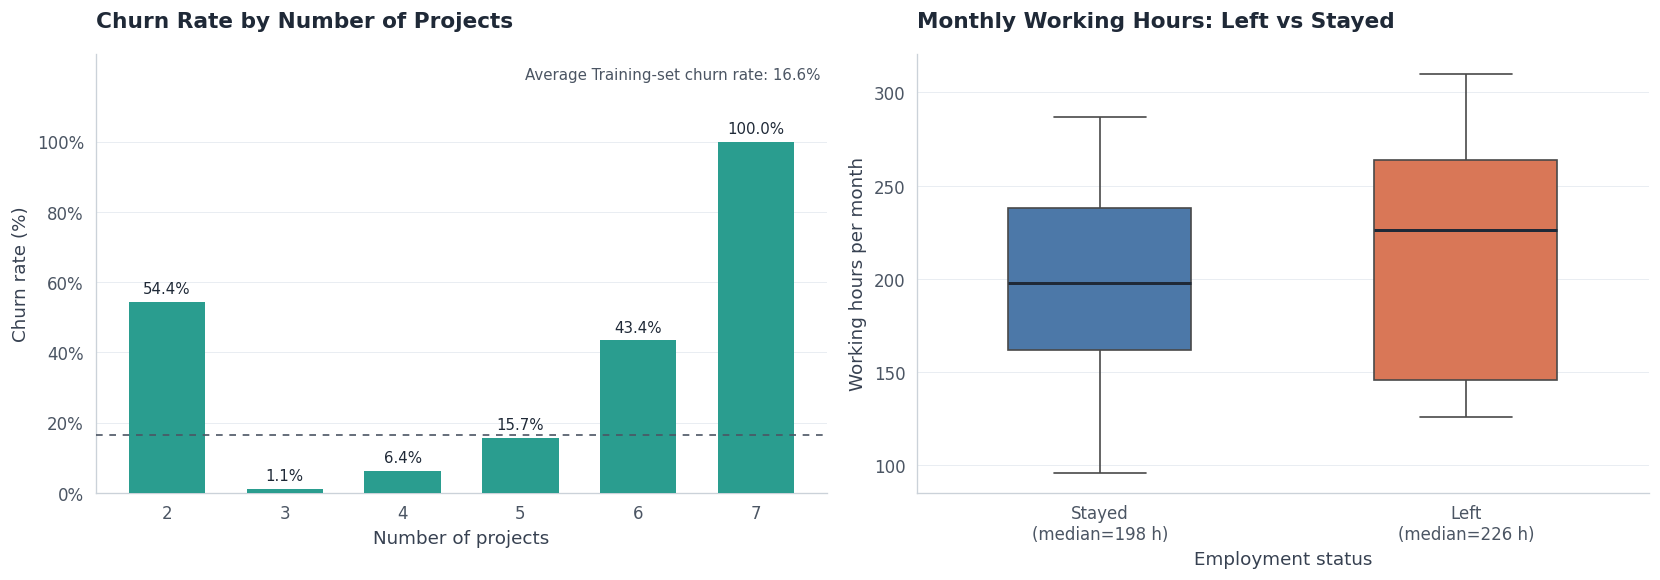

,Total employees,Employees who left,Churn rate (%)
number_project,,,
2,1102,599,54.36
3,2468,28,1.13
4,2563,163,6.36
5,1566,246,15.71
6,594,258,43.43
7,100,100,100.00


,Total employees,Median monthly hours
Employment status,,
Stayed,"6,999",198
Left,"1,394",226


In [15]:
def churn_summary(column, order=None):
    summary = data.groupby(column, observed=True)["left"].agg(n="size", left_count="sum")
    if order is not None:
        summary = summary.reindex(order)
    summary["churn_pct"] = summary["left_count"] / summary["n"] * 100
    return summary

def show_churn_table(summary, category_labels=None):
    table = summary.rename(index=category_labels or {}, columns={"n": "Total employees", "left_count": "Employees who left", "churn_pct": "Churn rate (%)"})
    display(table.style.format({"Churn rate (%)": "{:.2f}"}))

def plot_churn_rate(summary, ax, title, category_label, horizontal=False, show_counts=False, color=None):
    color = STATUS_COLORS["Left"] if color is None else color
    positions = np.arange(len(summary))
    rate_limit = max(30, summary["churn_pct"].max() * 1.25, overall_rate * 1.25)
    tick_step = 5 if rate_limit <= 40 else (10 if rate_limit <= 80 else 20)
    rate_ticks = np.arange(0, min(rate_limit, 100) + 0.01, tick_step)
    if horizontal:
        ax.barh(positions, summary["churn_pct"], color=color, height=0.65, edgecolor="none", zorder=3)
        ax.set_yticks(positions, [str(value) for value in summary.index])
        ax.invert_yaxis()
        ax.axvline(overall_rate, color="#4B5563", linestyle=(0, (4, 4)), linewidth=1, zorder=4)
        ax.text(overall_rate, 1.015, f"Average Training-set churn rate: {overall_rate:.1f}%", transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=9, color="#4B5563", clip_on=False)
        ax.set(xlabel="Churn rate (%)", ylabel=category_label, xlim=(0, rate_limit * 1.1))
        ax.set_xticks(rate_ticks)
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    else:
        ax.bar(positions, summary["churn_pct"], color=color, width=0.65, edgecolor="none", zorder=3)
        ax.set_xticks(positions, [str(value) for value in summary.index])
        ax.axhline(overall_rate, color="#4B5563", linestyle=(0, (4, 4)), linewidth=1, zorder=4)
        ax.text(0.99, 0.97, f"Average Training-set churn rate: {overall_rate:.1f}%", transform=ax.transAxes,
                ha="right", va="top", fontsize=9, color="#4B5563")
        ax.set(xlabel=category_label, ylabel="Churn rate (%)", ylim=(0, rate_limit))
        ax.set_yticks(rate_ticks)
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    for position, (_, row) in zip(positions, summary.iterrows()):
        rate, n = row["churn_pct"], int(row["n"])
        label = f"{rate:.1f}%"
        if horizontal:
            if show_counts:
                label += f" (n={n:,})"
            ax.annotate(label, (rate, position), xytext=(5, 0), textcoords="offset points", va="center", fontsize=9)
        else:
            if show_counts:
                label += f"\nn={n:,}"
            ax.annotate(label, (position, rate), xytext=(0, 5), textcoords="offset points", ha="center", fontsize=9)
    ax.set_title(title)
    style_axes(ax, grid_axis="x" if horizontal else "y")

project_summary = churn_summary("number_project", sorted(data["number_project"].unique()))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_churn_rate(project_summary, axes[0], "Churn Rate by Number of Projects", "Number of projects", show_counts=False, color=TOPIC_COLORS["projects"])
sns.boxplot(data=data, x="Status", y="average_montly_hours", order=STATUS_ORDER,
            hue="Status", hue_order=STATUS_ORDER, palette=STATUS_COLORS, dodge=False,
            width=0.5, linewidth=1, saturation=1,
            medianprops={"color": "#1F2937", "linewidth": 1.8},
            flierprops={"marker": "o", "markersize": 3, "alpha": 0.3}, ax=axes[1])
style_axes(axes[1])
if axes[1].get_legend() is not None:
    axes[1].get_legend().remove()
hour_medians = data.groupby("Status")["average_montly_hours"].median()
axes[1].set_xticks(range(2), [f"{status}\n(median={hour_medians[status]:.0f} h)" for status in STATUS_ORDER])
axes[1].set(title="Monthly Working Hours: Left vs Stayed", xlabel="Employment status", ylabel="Working hours per month")
plt.tight_layout()
plt.show()
show_churn_table(project_summary)
hours_summary = data.groupby("Status")["average_montly_hours"].agg(**{"Total employees": "size", "Median monthly hours": "median"}).reindex(STATUS_ORDER)
hours_summary.index.name = "Employment status"
display(hours_summary.style.format({"Total employees": "{:,.0f}", "Median monthly hours": "{:.0f}"}))

**Key takeaway:** Churn has a U-shaped relationship with number of projects: lowest at 3 (1.1%) and 4 (6.4%), then rising at 5 (15.7%), 6 (43.4%) and 7 (100%, n=100), but also high at 2 (54.4%). Leavers also have a wider spread of monthly hours (IQR ~146–264 vs ~162–238), suggesting both under- and over-worked employees leave.

## 3. Tenure and promotion
Compare churn rates by years at the company and promotion in the last five years. Tables show group sizes and the number who left.

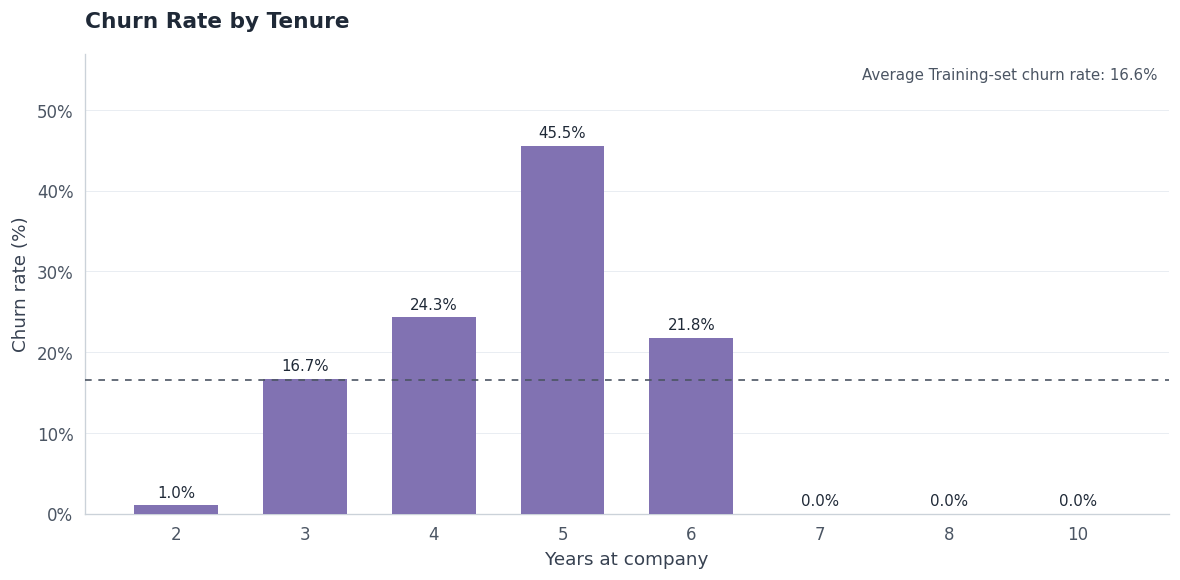

,Total employees,Employees who left,Churn rate (%)
time_spend_company,,,
2,2020,21,1.04
3,3639,608,16.71
4,1404,341,24.29
5,740,337,45.54
6,400,87,21.75
7,64,0,0.00
8,56,0,0.00
10,70,0,0.00


,Total employees,Employees who left,Churn rate (%)
Promotion in the last five years,,,
Not promoted,8257,1387,16.80
Promoted,136,7,5.15


In [16]:
tenure_summary = churn_summary("time_spend_company", sorted(data["time_spend_company"].unique()))
fig, ax = plt.subplots(figsize=(10, 5))
plot_churn_rate(tenure_summary, ax, "Churn Rate by Tenure", "Years at company", show_counts=False, color=TOPIC_COLORS["tenure"])
plt.tight_layout()
plt.show()
show_churn_table(tenure_summary)

promotion_summary = churn_summary("promotion_last_5years", [0, 1])
promotion_summary.index.name = "Promotion in the last five years"
show_churn_table(promotion_summary, {0: "Not promoted", 1: "Promoted"})

**Key takeaway:** Churn is concentrated in years 3-6 and peaks at year 5 (45.5%); it is near zero at year 2 (1.0%) and zero beyond year 6 (0 of 190 employees). Promoted employees churn less (5.1% vs 16.8%), but this group is small (n=136, only 7 leavers), so the estimate should be interpreted with caution. Promotion may also be confounded with tenure and salary.

## 4. Salary, department and work accidents
Compare churn rates across salary levels, departments and recorded work-accident groups. Departments are ranked by churn rate; tables show group sizes and the number who left.

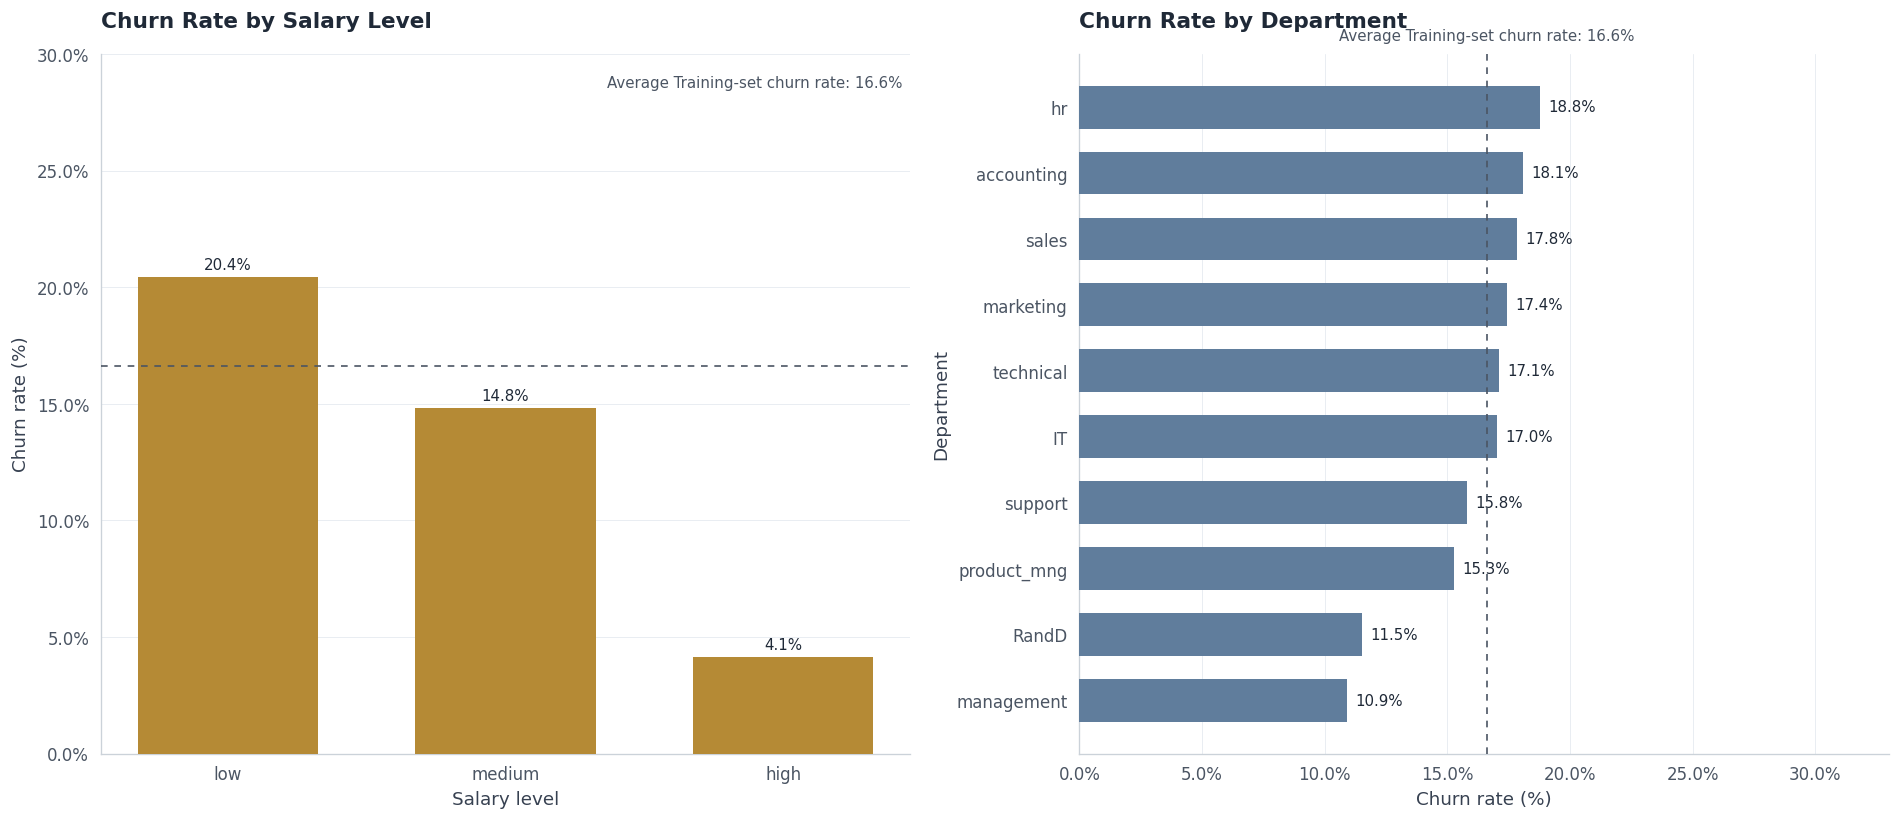

,Total employees,Employees who left,Churn rate (%)
salary,,,
low,4028,823,20.43
medium,3662,542,14.80
high,703,29,4.13


,Total employees,Employees who left,Churn rate (%)
Departments,,,
hr,421,79,18.76
accounting,437,79,18.08
sales,2249,401,17.83
marketing,476,83,17.44
technical,1583,271,17.12
IT,682,116,17.01
support,1284,203,15.81
product_mng,491,75,15.27
RandD,486,56,11.52


,Total employees,Employees who left,Churn rate (%)
Recorded work accident,,,
No recorded accident,7091,1320,18.62
Recorded accident,1302,74,5.68


In [17]:
salary_summary = churn_summary("salary", ["low", "medium", "high"])
department_summary = churn_summary("Departments").sort_values("churn_pct", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
plot_churn_rate(salary_summary, axes[0], "Churn Rate by Salary Level", "Salary level", show_counts=False, color=TOPIC_COLORS["salary"])
plot_churn_rate(department_summary, axes[1], "Churn Rate by Department", "Department", horizontal=True, show_counts=False, color=TOPIC_COLORS["department"])
plt.tight_layout()
plt.show()
show_churn_table(salary_summary)
show_churn_table(department_summary)

accident_summary = churn_summary("Work_accident", [0, 1])
accident_summary.index.name = "Recorded work accident"
show_churn_table(accident_summary, {0: "No recorded accident", 1: "Recorded accident"})

**Key takeaway:** Churn decreases sharply with salary (low 20.4%, medium 14.8%, high 4.1%). Departments differ only modestly: most fall between 15% and 19%, with R&D (11.5%) and management (10.9%) lowest, and these groups are small. Employees with a recorded work accident have lower churn (5.7% vs 18.6%), which is counterintuitive and may reflect confounding rather than any protective effect.

## Overall takeaway for classification
The training-data EDA suggests that employee churn is associated with several features rather than a single factor. Satisfaction, workload, tenure and salary show clear differences in churn patterns. Evaluation scores should also be retained, since employees who leave do not necessarily have low evaluations.